# Transport innovations and covariance estimation

A runnable synthetic example using the research package. No market data, internet connection, or notebook-specific execution features are required. All numerical routines remain in `spde_covariance`; the notebook specifies an experiment, calls the APIs, and inspects the results.

The exact exponential submodel is closed under the right-shift semigroup. Its source covariance is \(C\), whereas the normalized adjusted increment has covariance
\[
V_\Delta=\Delta^{-1}\int_0^\Delta S_r C S_r^*\,dr.
\]
The estimator below targets **innovation covariance \(V_\Delta\)**. It does not calibrate a curve or predict future curves.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.geometry import diagnose_design
from spde_covariance.trajectories import extract_innovations, simulate_transport
from spde_covariance.transport import ExponentialTransport
from spde_covariance.workflow import fit_innovation_covariance

SEED = 1729
DELTA = 1 / 52
N_INTERVALS = 1024
NUMERICAL_ERROR_BUDGET = 1e-5

## Simulate a transport trajectory and extract innovations

The dates are in years and the source covariance is deterministic and constant. Full orthonormal curve coefficients are observed in this illustration. Extraction uses the actual weekly interval length and subtracts the transported preceding curve before dividing by \(\sqrt{\Delta}\). There is zero additional mild drift and no observation noise.

In [2]:
model = ExponentialTransport(rates=[0.6, 1.0, 2.0, 4.0])
source_covariance = np.diag([0.4, 0.3, 0.2, 0.1])
times = np.arange(N_INTERVALS + 1) * DELTA
simulation = simulate_transport(model, times, source_covariance, seed=SEED)
innovations = extract_innovations(simulation.trajectory, model)

assert innovations.n_intervals == N_INTERVALS
assert innovations.basis_id == model.basis_id
print(f"Seed: {SEED}; intervals: {innovations.n_intervals}; step: {DELTA:.8f} year")
print(f"Propagation: {innovations.propagation_method}; unit: {innovations.innovation_unit}")

Seed: 1729; intervals: 1024; step: 0.01923077 year
Propagation: exact_transport; unit: arbitrary curve unit/sqrt(year)


## Fit the common innovation covariance

The common covariance assumption is declared explicitly because it is part of this synthetic data-generating model. All dates receive uniform weights. The full PSD matrix is fitted with a trace cap; no factor rank is imposed. Latent source and innovation covariance truths are not estimator inputs. A numerical-error certificate is required before the high-level routine returns successfully.

In [3]:
fitted = fit_innovation_covariance(
    innovations,
    regularization=1e-3,
    trace_cap=2.0,
    covariance_assumption="common",
    numerical_error_budget=NUMERICAL_ERROR_BUDGET,
)

assert fitted.estimate.converged
assert fitted.estimate.covariance_error_bound <= NUMERICAL_ERROR_BUDGET
assert fitted.estimate.min_eigenvalue >= -1e-12
assert fitted.estimate.trace <= 2.0 + 1e-12
print(f"Target: {fitted.target}")
print(f"Certified numerical covariance error: {fitted.estimate.covariance_error_bound:.3g}")

Target: common-step innovation covariance V_delta
Certified numerical covariance error: 2.31e-08


## Evaluate against synthetic truth

Only now use the known model covariance for evaluation. Statistical estimation error and optimization error are different quantities. The source-to-innovation difference below also shows why \(V_\Delta\) and \(C\) retain separate labels.

In [4]:
true_innovation_covariance = model.innovation_covariance(source_covariance, DELTA)
relative_hs_error = np.linalg.norm(fitted.covariance - true_innovation_covariance) / np.linalg.norm(
    true_innovation_covariance
)
innovation_source_difference = np.linalg.norm(true_innovation_covariance - source_covariance)

assert relative_hs_error < 0.2
assert innovation_source_difference > 0
print(f"Relative Hilbert-Schmidt estimation error: {relative_hs_error:.3%}")
print(f"Innovation-versus-source HS difference: {innovation_source_difference:.5f}")

Relative Hilbert-Schmidt estimation error: 5.821%
Innovation-versus-source HS difference: 0.01606


## Compare evaluation kernels

For an evaluation row \(E(x)\), the plotted kernel is \(E(x)V_\Delta E(y)^\top\). This is the evaluation covariance induced by the Hilbert-space covariance, rather than an integral-kernel convention. The first two panels share their color scale; the third isolates estimation error.

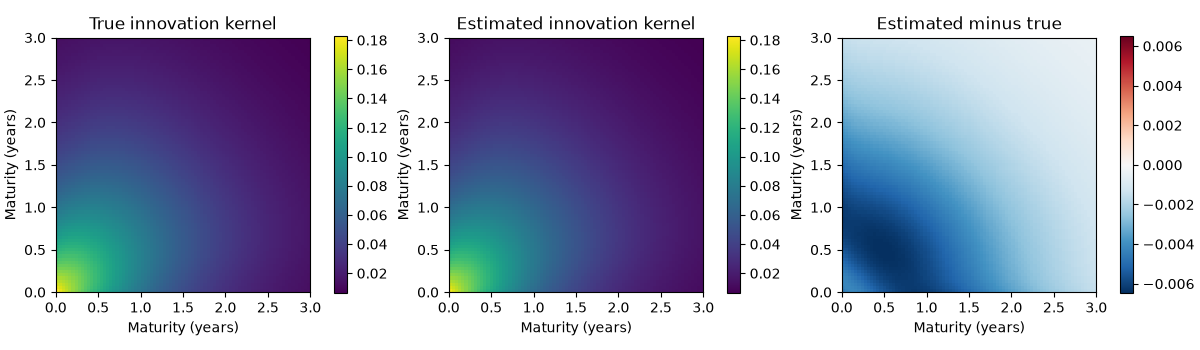

In [5]:
maturities = np.linspace(0, 3, 81)
evaluation = model.evaluate(maturities)
true_kernel = evaluation @ true_innovation_covariance @ evaluation.T
estimated_kernel = evaluation @ fitted.covariance @ evaluation.T
kernel_error = estimated_kernel - true_kernel
common_min = min(true_kernel.min(), estimated_kernel.min())
common_max = max(true_kernel.max(), estimated_kernel.max())
error_limit = max(float(np.max(np.abs(kernel_error))), 1e-12)

figure, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
for axis, values, title in zip(
    axes[:2],
    [true_kernel, estimated_kernel],
    ["True innovation kernel", "Estimated innovation kernel"],
):
    image = axis.imshow(
        values,
        origin="lower",
        extent=(0, 3, 0, 3),
        vmin=common_min,
        vmax=common_max,
        cmap="viridis",
    )
    axis.set(title=title, xlabel="Maturity (years)", ylabel="Maturity (years)")
    figure.colorbar(image, ax=axis, shrink=0.8)
image = axes[2].imshow(
    kernel_error,
    origin="lower",
    extent=(0, 3, 0, 3),
    vmin=-error_limit,
    vmax=error_limit,
    cmap="RdBu_r",
)
axes[2].set(title="Estimated minus true", xlabel="Maturity (years)", ylabel="Maturity (years)")
figure.colorbar(image, ax=axes[2], shrink=0.8)
plt.show()

## Inspect a sparse observation design

As a separate geometric illustration, observe one orthonormal coordinate at each date. All coordinates appear across the dates, yet no date observes their products. The lifted observation Gram operator therefore identifies coordinate variances while leaving contemporaneous cross-covariances unidentified. This example concerns pair-observation geometry; it is not a fitted comparison using a different information set.

In [6]:
identity = np.eye(model.dimension)
sparse_operators = [identity[index : index + 1] for index in range(model.dimension)]
variance_target = np.outer(identity[0], identity[0])
cross_target = (np.outer(identity[0], identity[1]) + np.outer(identity[1], identity[0])) / 2
sparse_diagnostics = diagnose_design(
    sparse_operators,
    targets={"first_variance": variance_target, "cross_covariance": cross_target},
    regularization=1e-3,
)

assert sparse_diagnostics["rank"] == model.dimension
assert sparse_diagnostics["targets"]["first_variance"]["identified"]
assert not sparse_diagnostics["targets"]["cross_covariance"]["identified"]
print(f"Lifted Gram rank: {sparse_diagnostics['rank']} / {sparse_diagnostics['dimension']}")
print("Gram eigenvalues:", sparse_diagnostics["eigenvalues"])
print(
    "Cross-covariance relative nullspace residual:",
    sparse_diagnostics["targets"]["cross_covariance"]["nullspace_relative_residual"],
)

Lifted Gram rank: 4 / 10
Gram eigenvalues: [0.   0.   0.   0.   0.   0.   0.25 0.25 0.25 0.25]
Cross-covariance relative nullspace residual: 1.0


The successful full-coordinate fit is a controlled implementation check. Partial contract observations can identify fewer covariance quantities, and a PSD fit alone does not settle that identification question. Irregular interval pooling, noisy-price differencing, confidence intervals, market calibration, and forecasting require their own assumptions and remain outside this demonstration.

Re-run all cells from a fresh kernel, or verify execution without Jupyter using `python scripts/check_notebook.py`. The checker captures text and figures in memory and leaves this output-clean notebook unchanged by default.